# NAG (Nesterov Accelerated Gradient) Optimizer

- It is a variant of momentum optimizer, which tries to fix the problem of oscillation around the minimum.

- It damps the oscillation around the minimum.

- In momentum optimizer we update the weight using both the current gradient and the previous velocity. 

- But in NAG, we first make a jump in the direction of the previous accumulated gradient (velocity), and then calculate the gradient at that new position and goes in that direction accordingly. 

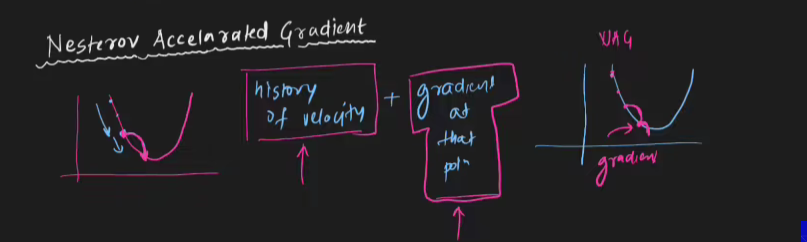

# Mathematical Formulation

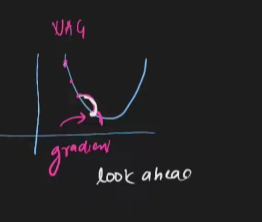

- We first calculate the lookahead position (the white dot) using the previous velocity 

- And then calculate the gradient at that lookahead position and update the weights accordingly.

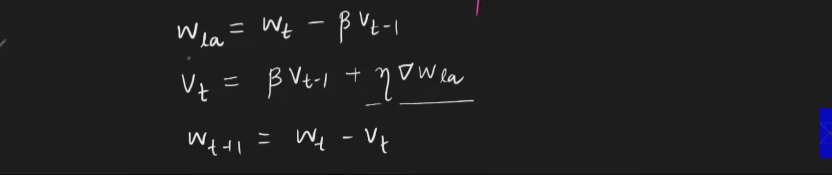


# Nesterov Accelerated Gradient (NAG)

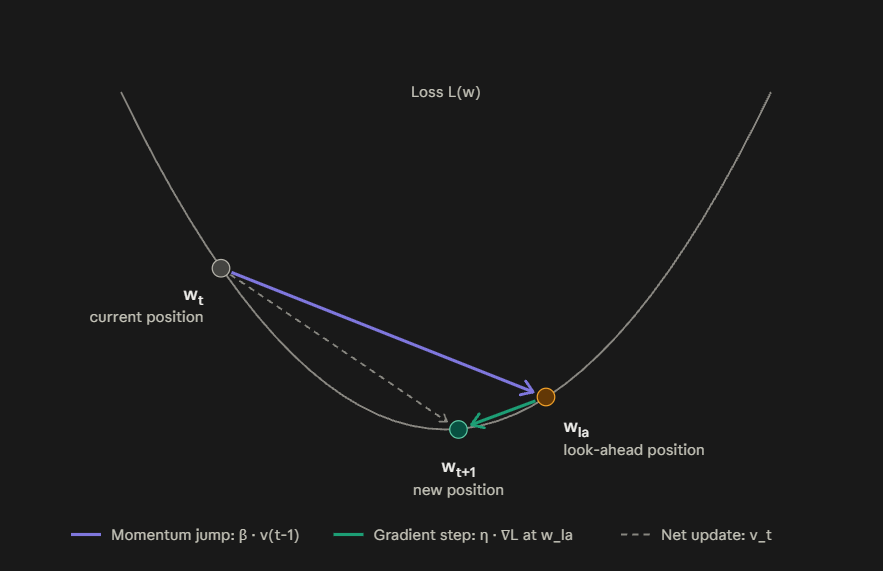

## Idea
- Plain momentum: compute the slope at the current point, then add the velocity history.
- NAG: first jump ahead using the velocity history, then compute the slope at that look-ahead point.
- Result: you see where momentum is about to take you and correct before overshooting.

## Symbols
- $w_t$ = current position (weights)
- $w_{la}$ = look-ahead position
- $v_{t-1}$ = previous velocity (history of past steps)
- $v_t$ = new velocity
- $\beta$ = momentum factor (usually about 0.9)
- $\eta$ = learning rate
- $\nabla L(w_{la})$ = gradient (slope) of the loss at the look-ahead point

## Steps

1. Look ahead: move to where momentum alone would carry you.

$$
w_{la} = w_t - \beta \, v_{t-1}
$$

2. Gradient at look-ahead: old momentum plus a correction from the slope at $w_{la}$, not at $w_t$.

$$
v_t = \beta \, v_{t-1} + \eta \, \nabla L(w_{la})
$$

3. Update:

$$
w_{t+1} = w_t - v_t
$$

## Handy simplification
- Combining the three steps:

$$
w_{t+1} = w_{la} - \eta \, \nabla L(w_{la})
$$

- Meaning: a normal gradient step, but starting from the look-ahead point.

- For comparison, plain momentum would be:

$$
w_{t+1} = w_t - \beta \, v_{t-1} - \eta \, \nabla L(w_t)
$$
- We so we update the weight based on the previous velocity and the gradient at the current position, not the look-ahead position. Which leads to overshooting and oscillation around the minimum.

## Diagram (loss bowl)
- $w_t$ sits on the left slope of the bowl.
- Momentum jump $\beta \, v_{t-1}$ carries you to $w_{la}$, just past the minimum.
- The slope at $w_{la}$ points back toward the minimum.
- Gradient step $\eta \, \nabla L(w_{la})$ pulls you back to $w_{t+1}$, near the bottom.
- Net move from $w_t$ to $w_{t+1}$ is $v_t$.

## Why it is better than plain momentum
- Plain momentum reacts only after overshooting.
- NAG peeks ahead, so the correction arrives earlier.
- Less oscillation around the minimum, usually faster convergence.

## One-line analogy
- A ball rolling down a bowl that can see the slope ahead of it, so it brakes before it overshoots.

# Geometrical Intuition

### Momentum
- The next step combines two things: the previous velocity and the slope at the current position $w_t$.
- The slope is measured before the momentum jump, so it describes where you were, not where you are about to land.
- If momentum is carrying you past the minimum, the gradient does not know yet, so you overshoot and oscillate.

### NAG (Nesterov Accelerated Gradient)
- First take a step in the direction of the previous velocity to reach the look-ahead point $w_{la}$.
- Then measure the slope at $w_{la}$, not at $w_t$.
- If $w_{la}$ is already past the minimum, its slope points back, so the correction pulls you in before you overshoot.


# Disadvantageof NAG

- Because it damps the oscillation, it might get stuck in a local minimum, where plain momentum would have enough inertia to escape.

# Code for diff optimizers

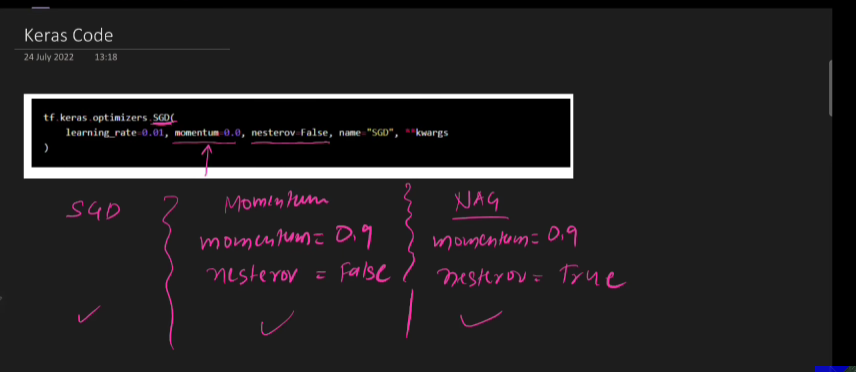